# Análisis de errores de P1 | Equipo 45

El MAE global resume el error en un número, pero no dice **dónde** falla el modelo. Este cuaderno descompone el error del modelo registrado como `champion` en `mibici-p1-demanda` (el de la pregunta P1: salidas esperadas por estación y hora) por hora del día, por nivel de demanda y por estación.

Alcance y precauciones:

- Se usa **solo validación** (julio y agosto de 2026). Septiembre no se abre, para no tomar decisiones mirando la prueba.
- Requiere haber entrenado antes (`python -m mibici.train --question P1`), porque carga el modelo desde el registro local de MLflow.
- Las tablas y figuras son agregados por hora, nivel de demanda y estación; no contienen datos de personas usuarias.
- El error se define como `observado - predicción`: un valor positivo significa que el modelo **subestima** la demanda.

In [1]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from mibici import config as cfg

NOMBRE = "mibici-p1-demanda"
URI = f"models:/{NOMBRE}@champion"

mlflow.set_tracking_uri(cfg.TRACKING_URI)
cliente = mlflow.tracking.MlflowClient()
version = cliente.get_model_version_by_alias(NOMBRE, "champion")
columnas = mlflow.models.get_model_info(URI).signature.inputs.input_names()
modelo = mlflow.sklearn.load_model(URI)
corrida = cliente.get_run(version.run_id)

print("Modelo:", NOMBRE, "versión", version.version, "| run:", corrida.info.run_name)
print("Columnas de entrada:", columnas)

Modelo: mibici-p1-demanda versión 3 | run: P1_hgb_poisson_estacion_h1
Columnas de entrada: ['hour', 'weekday', 'is_weekend', 'month', 'departures_lag_1', 'departures_lag_24', 'departures_lag_168', 'departures_mean_24', 'departures_mean_168', 'station_id']


## 1. Predicciones sobre validación

Se carga la tabla de variables de P1, se queda con la partición `val` y se predice con el modelo registrado. Como comprobación, el MAE recalculado debe coincidir con el `val_mae` que MLflow guardó al entrenar.

In [2]:
datos = pd.read_parquet(cfg.FEATURE_FILES["p1"])
val = datos[datos["split"] == "val"].copy()
val["prediccion"] = modelo.predict(val[columnas])
val["error"] = val["target_departures"] - val["prediccion"]
val["error_abs"] = val["error"].abs()

mae = val["error_abs"].mean()
wape = val["error_abs"].sum() / val["target_departures"].sum()
registrado = corrida.data.metrics["val_mae"]

print(f"Filas de validación: {len(val):,} | estaciones: {val['station_id'].nunique()}")
print(f"MAE recalculado: {mae:.6f} | MAE registrado en MLflow: {registrado:.6f}")
print(f"WAPE global: {wape:.4f} | sesgo medio (observado - predicción): {val['error'].mean():.4f}")
assert np.isclose(mae, registrado, rtol=1e-6)

Filas de validación: 665,747 | estaciones: 470
MAE recalculado: 0.749792 | MAE registrado en MLflow: 0.749792
WAPE global: 0.6403 | sesgo medio (observado - predicción): -0.0028


## 2. Error por hora del día

Se compara, para cada hora, la demanda media, el MAE, el WAPE (error absoluto total entre demanda total) y la participación de esa hora en el error absoluto total. Un WAPE alto en horas de poca demanda es esperable; lo relevante es dónde se concentra el error en términos absolutos.

In [3]:
grupo = val.groupby("hour")
por_hora = pd.DataFrame(
    {
        "demanda_media": grupo["target_departures"].mean(),
        "mae": grupo["error_abs"].mean(),
        "sesgo": grupo["error"].mean(),
        "error_abs_total": grupo["error_abs"].sum(),
    }
)
por_hora["wape"] = por_hora["error_abs_total"] / grupo["target_departures"].sum()
por_hora["participacion_error"] = por_hora["error_abs_total"] / por_hora["error_abs_total"].sum()
por_hora.round(3)

,demanda_media,mae,sesgo,error_abs_total,wape,participacion_error
hour,,,,,,
0,0.196,0.267,-0.002,7397.803,1.363,0.015
1,0.001,0.004,-0.002,117.723,3.364,0.000
2,0.000,0.003,-0.003,85.909,17.182,0.000
3,0.000,0.003,-0.003,81.870,81.870,0.000
4,0.000,0.003,-0.003,83.895,27.965,0.000
5,0.225,0.264,-0.024,7317.517,1.174,0.015
6,0.802,0.608,-0.029,16848.031,0.758,0.034
7,1.599,0.931,0.006,25823.961,0.582,0.052
8,2.099,1.136,0.057,31502.728,0.541,0.063


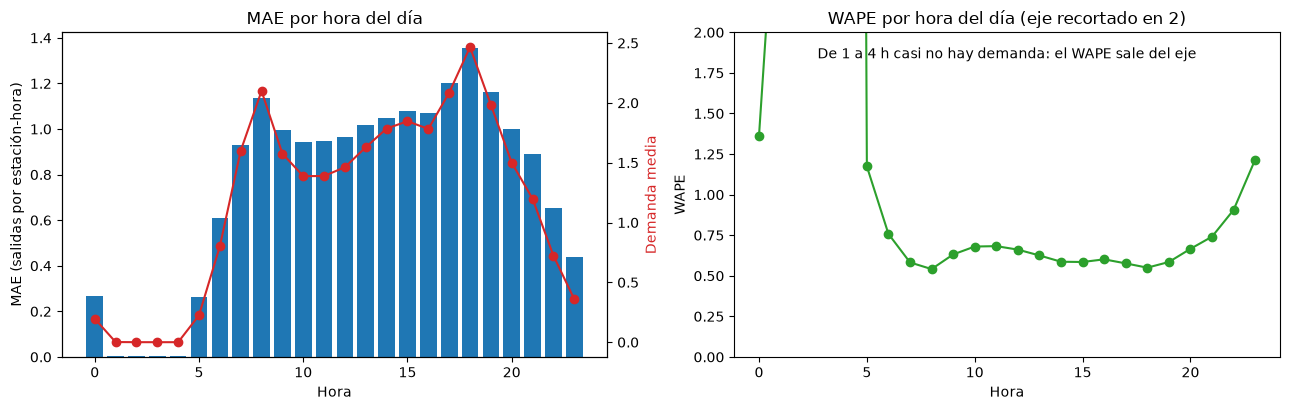

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
ejes[0].bar(por_hora.index, por_hora["mae"], color="tab:blue")
ejes[0].set(title="MAE por hora del día", xlabel="Hora", ylabel="MAE (salidas por estación-hora)")
eje_demanda = ejes[0].twinx()
eje_demanda.plot(por_hora.index, por_hora["demanda_media"], color="tab:red", marker="o")
eje_demanda.set_ylabel("Demanda media", color="tab:red")
ejes[1].plot(por_hora.index, por_hora["wape"], marker="o", color="tab:green")
ejes[1].set(
    title="WAPE por hora del día (eje recortado en 2)", xlabel="Hora", ylabel="WAPE", ylim=(0, 2)
)
ejes[1].text(
    0.5, 0.92, "De 1 a 4 h casi no hay demanda: el WAPE sale del eje", transform=ejes[1].transAxes, ha="center"
)
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "p1_errores_hora.png", dpi=130)
plt.show()

## 3. Error por nivel de demanda

El nivel de demanda se mide con la media de las últimas 168 horas de cada fila (`departures_mean_168`), que está disponible al momento de predecir; así los grupos no dependen de la demanda que se quiere predecir. Se divide en diez deciles de igual tamaño, del 1 (menor demanda reciente) al 10 (mayor).

In [5]:
val["decil"] = pd.qcut(val["departures_mean_168"].rank(method="first"), 10, labels=range(1, 11))
grupo = val.groupby("decil", observed=True)
por_decil = pd.DataFrame(
    {
        "demanda_reciente_media": grupo["departures_mean_168"].mean(),
        "demanda_media": grupo["target_departures"].mean(),
        "mae": grupo["error_abs"].mean(),
        "sesgo": grupo["error"].mean(),
        "error_abs_total": grupo["error_abs"].sum(),
    }
)
por_decil["wape"] = por_decil["error_abs_total"] / grupo["target_departures"].sum()
por_decil["participacion_error"] = por_decil["error_abs_total"] / por_decil["error_abs_total"].sum()
por_decil.round(3)

,demanda_reciente_media,demanda_media,mae,sesgo,error_abs_total,wape,participacion_error
decil,,,,,,,
1,0.138,0.161,0.260,-0.017,17313.291,1.612,0.035
2,0.258,0.268,0.363,-0.008,24145.589,1.353,0.048
3,0.363,0.368,0.435,-0.007,28936.320,1.181,0.058
4,0.490,0.491,0.506,-0.006,33699.545,1.030,0.068
5,0.661,0.664,0.590,-0.001,39281.725,0.889,0.079
6,0.910,0.911,0.705,-0.009,46959.188,0.774,0.094
7,1.219,1.222,0.837,-0.010,55724.167,0.685,0.112
8,1.574,1.562,0.956,0.004,63618.691,0.612,0.127
9,2.093,2.078,1.122,0.005,74727.432,0.540,0.150


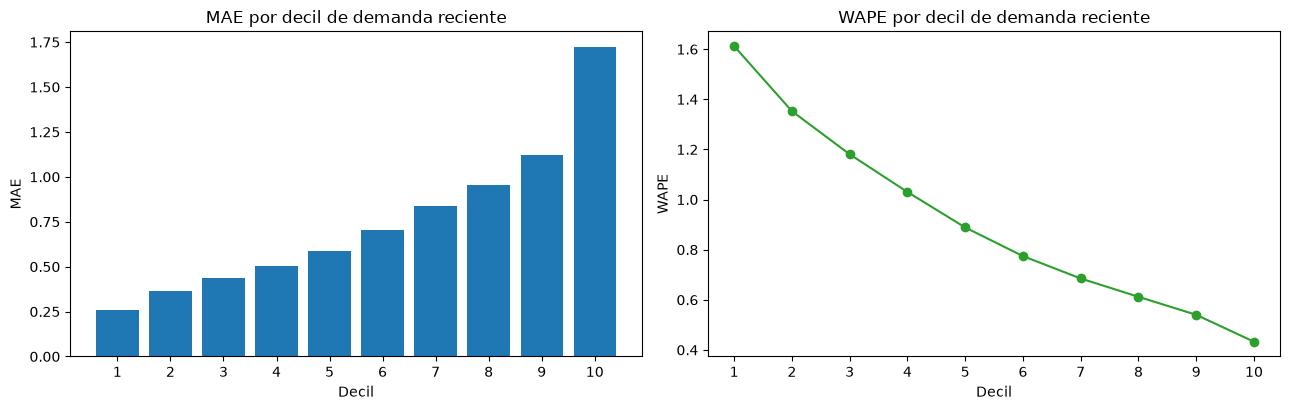

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
ejes[0].bar(por_decil.index.astype(int), por_decil["mae"], color="tab:blue")
ejes[0].set(title="MAE por decil de demanda reciente", xlabel="Decil", ylabel="MAE")
ejes[1].plot(por_decil.index.astype(int), por_decil["wape"], marker="o", color="tab:green")
ejes[1].set(title="WAPE por decil de demanda reciente", xlabel="Decil", ylabel="WAPE")
for eje in ejes:
    eje.set_xticks(range(1, 11))
fig.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "p1_errores_decil.png", dpi=130)
plt.show()

## 4. Estaciones con mayor error absoluto total

Se suman los errores absolutos de cada estación en validación y se listan las diez mayores. Se muestra también su participación en el error total y su demanda, para distinguir las estaciones que fallan porque son grandes de las que fallan por ser difíciles de predecir (WAPE alto).

In [7]:
nombres = pd.read_parquet(cfg.STATIONS_FILE).set_index("station_id")["name"]
grupo = val.groupby("station_id")
estaciones = pd.DataFrame(
    {
        "horas": grupo.size(),
        "demanda_media": grupo["target_departures"].mean(),
        "mae": grupo["error_abs"].mean(),
        "sesgo": grupo["error"].mean(),
        "error_abs_total": grupo["error_abs"].sum(),
    }
)
estaciones["wape"] = estaciones["error_abs_total"] / grupo["target_departures"].sum()
estaciones["participacion_error"] = estaciones["error_abs_total"] / estaciones["error_abs_total"].sum()
principales = estaciones.sort_values("error_abs_total", ascending=False).head(10).join(nombres)
principales[["name", "horas", "demanda_media", "mae", "wape", "sesgo", "participacion_error"]].round(3)

,name,horas,demanda_media,mae,wape,sesgo,participacion_error
station_id,,,,,,,
51,(GDL-049) Lopez Cotilla / Penitenciaría,1488,13.433,4.597,0.342,0.577,0.014
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,1488,5.856,3.565,0.609,-0.116,0.011
50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,1488,7.114,2.961,0.416,0.044,0.009
54,(GDL-052) Av. Juarez /16 de Septiembre,1488,6.724,2.583,0.384,0.116,0.008
271,(GDL-198) Av. Alcalde / C. Hospital,1488,7.625,2.503,0.328,-0.075,0.007
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,1488,6.896,2.382,0.345,-0.151,0.007
52,(GDL-050) C.Pedro Moreno /Federalismo,1488,5.772,2.208,0.382,-0.258,0.007
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,1488,5.671,1.988,0.351,0.004,0.006
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,1488,4.845,1.912,0.395,-0.027,0.006


In [8]:
total = estaciones["participacion_error"].sort_values(ascending=False)
print(f"Las 10 estaciones con más error concentran {total.head(10).sum():.1%} del error absoluto total")
print(f"Son {10 / len(estaciones):.1%} de las {len(estaciones)} estaciones de validación")
print(f"Las 50 con más error concentran {total.head(50).sum():.1%}")
print(f"WAPE de estas 10: {principales['error_abs_total'].sum() / grupo['target_departures'].sum().loc[principales.index].sum():.3f} | WAPE del resto: {(estaciones['error_abs_total'].sum() - principales['error_abs_total'].sum()) / (val['target_departures'].sum() - grupo['target_departures'].sum().loc[principales.index].sum()):.3f}")

Las 10 estaciones con más error concentran 7.9% del error absoluto total
Son 2.1% de las 470 estaciones de validación
Las 50 con más error concentran 24.9%
WAPE de estas 10: 0.390 | WAPE del resto: 0.678


## 5. Dónde falla el modelo y qué probar después

Resultados con el `champion` de esta ejecución (`P1_hgb_poisson_estacion_h1`, el modelo con menor `val_mae` al momento de escribir este análisis), en validación. Si el `champion` cambia, vuelve a ejecutar el cuaderno y revisa estas cifras:

- **Dónde se concentra el error absoluto.** Sigue a la demanda: las horas pico (7 a 9 h y 17 a 19 h) son 6 de las 24 horas y reúnen 38% del error absoluto total, con el máximo a las 18 h (7.5%); en cambio, de 1 a 4 h casi no hay demanda ni error.
- **Dónde es peor en términos relativos.** El WAPE cae de 1.61 en el decil 1 de demanda reciente a 0.43 en el decil 10, y por hora va de 1.2 a 1.4 de madrugada y por la noche a 0.54 a 0.58 en las horas pico. El decil 10 por sí solo concentra 23% del error absoluto. El WAPE global de 64% sale sobre todo de las estaciones-hora con poca demanda, donde un conteo de 0 a 2 salidas tiene mucha variación aleatoria que ningún modelo puede explicar; esto es una hipótesis razonable, no se midió aquí el ruido irreducible.
- **Sin sesgo sistemático.** El sesgo medio es -0.003 y por decil queda entre -0.017 y 0.022 (observado menos predicción). La subestimación más visible aparece a las 18 h (0.073) y en el decil 10 (0.022).
- **No es un problema de pocas estaciones.** Las 10 estaciones con más error suman 7.9% del error total (2.1% de las estaciones) y las 50 primeras, 24.9%. Son estaciones grandes del centro (demanda media de 4 a 13 salidas por hora) cuyo WAPE (0.39) es menor que el del resto (0.68): fallan por tamaño, no por ser difíciles de predecir. La estación con mayor error es `(GDL-049) Lopez Cotilla / Penitenciaría`, con 1.4% del total.

Qué se podría probar después, sin usar septiembre para decidir:

- Variables que expliquen la variación en las horas y estaciones de mayor demanda: calendario de feriados y eventos, y clima, si se consigue una fuente reproducible.
- Una métrica adicional que no penalice tanto los conteos pequeños (por ejemplo la desviación de Poisson) y reportar WAPE por decil junto con el global.
- Revisar con más detalle la subestimación de las 18 h y de las estaciones de mayor demanda, por ejemplo con rezagos de la misma hora de días anteriores.
